<a href="https://colab.research.google.com/github/irishafari-svg/momo-fraud-detection/blob/main/momo_fraud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
CT
import pandas as pd
import numpy as np

np.random.seed(42)
n = 20000

types = np.random.choice(['PAYMENT', 'TRANSFER', 'CASH_OUT', 'CASH_IN', 'DEBIT'], size=n, p=[0.35, 0.25, 0.20, 0.10, 0.10])

# Fraud is rare, but much more likely in TRANSFER and CASH_OUT
fraud_prob = np.where(np.isin(types, ['TRANSFER', 'CASH_OUT']), 0.02, 0.001)
isFraud = np.random.binomial(1, fraud_prob)

amount = np.random.lognormal(mean=8, sigma=1.2, size=n).round(2)
oldbalanceOrg = np.random.lognormal(mean=9, sigma=1.0, size=n).round(2)
newbalanceOrig = np.where(isFraud==1, 0, (oldbalanceOrg - amount).clip(min=0)).round(2)
oldbalanceDest = np.random.lognormal(mean=8, sigma=1.0, size=n).round(2)
newbalanceDest = (oldbalanceDest + amount).round(2)

df = pd.DataFrame({
    'step': np.random.randint(1, 744, size=n),
    'type': types,
    'amount': amount,
    'oldbalanceOrg': oldbalanceOrg,
    'newbalanceOrig': newbalanceOrig,
    'oldbalanceDest': oldbalanceDest,
    'newbalanceDest': newbalanceDest,
    'isFraud': isFraud
})

print(df.shape)
print(df['isFraud'].value_counts(normalize=True))
print(df.head())
print(df.groupby('type')['isFraud'].mean())

(20000, 8)
isFraud
0    0.9907
1    0.0093
Name: proportion, dtype: float64
   step      type   amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0    14  TRANSFER  1509.54        3116.98         1607.44         1579.84   
1   271     DEBIT  2126.65       63608.09        61481.44         3332.35   
2   718  CASH_OUT  2430.62        6442.47         4011.85         1750.23   
3   629  TRANSFER  2347.69        2511.81          164.12         2015.66   
4   189   PAYMENT  1374.85        7224.10         5849.25          816.92   

   newbalanceDest  isFraud  
0         3089.38        0  
1         5459.00        0  
2         4180.85        0  
3         4363.35        0  
4         2191.77        0  
type
CASH_IN     0.000497
CASH_OUT    0.018725
DEBIT       0.000000
PAYMENT     0.000860
TRANSFER    0.020694
Name: isFraud, dtype: float64


In [6]:
# 1. Which type has the most fraud?
print(df.groupby('type')['isFraud'].mean().sort_values(ascending=False))

# 2. How big are fraud vs legit?
print(df.groupby('isFraud')['amount'].describe())

type
TRANSFER    0.020694
CASH_OUT    0.018725
PAYMENT     0.000860
CASH_IN     0.000497
DEBIT       0.000000
Name: isFraud, dtype: float64
           count         mean           std     min      25%       50%  \
isFraud                                                                  
0        19814.0  6067.102763  10174.801358   14.03  1314.97  2985.035   
1          186.0  5478.078656   7040.087986  251.82  1205.15  3109.050   

               75%        max  
isFraud                        
0        6689.1350  261293.61  
1        6520.8925   42172.14  


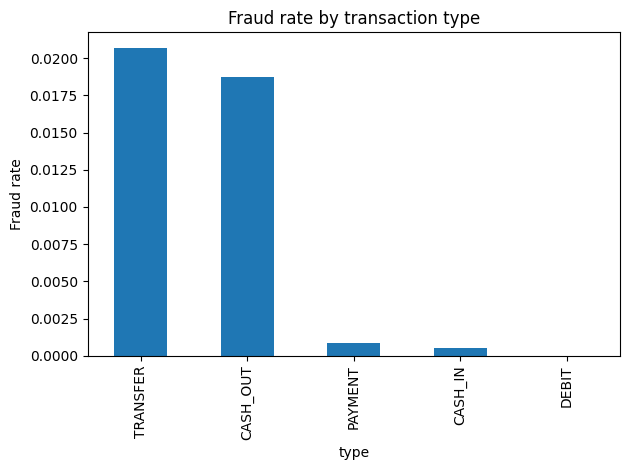

In [7]:
import matplotlib.pyplot as plt

fraud_rate = df.groupby('type')['isFraud'].mean().sort_values(ascending=False)
fraud_rate.plot(kind='bar')
plt.title('Fraud rate by transaction type')
plt.ylabel('Fraud rate')
plt.tight_layout()
plt.savefig('fraud_rate.png')
plt.show()

In [8]:
# Keep only what we need
df2 = df[['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud']].copy()

# Feature 1: Did the sender balance go to zero after?
df2['sender_emptied'] = (df2['newbalanceOrig'] == 0).astype(int)

# Feature 2: How much did the destination balance change?
df2['dest_change'] = df2['newbalanceDest'] - df2['oldbalanceDest']

# Turn type into numbers for the model
df2 = pd.get_dummies(df2, columns=['type'], drop_first=True)

print(df2.head())
print(df2.shape)

   step   amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0    14  1509.54        3116.98         1607.44         1579.84   
1   271  2126.65       63608.09        61481.44         3332.35   
2   718  2430.62        6442.47         4011.85         1750.23   
3   629  2347.69        2511.81          164.12         2015.66   
4   189  1374.85        7224.10         5849.25          816.92   

   newbalanceDest  isFraud  sender_emptied  dest_change  type_CASH_OUT  \
0         3089.38        0               0      1509.54          False   
1         5459.00        0               0      2126.65          False   
2         4180.85        0               0      2430.62           True   
3         4363.35        0               0      2347.69          False   
4         2191.77        0               0      1374.85          False   

   type_DEBIT  type_PAYMENT  type_TRANSFER  
0       False         False           True  
1        True         False          False  
2       False    

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

X = df2.drop(columns=['isFraud'])
y = df2['isFraud']

# Convert True/False to 1/0
X = X.astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

[[3962    0]
 [  19   19]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3962
           1       1.00      0.50      0.67        38

    accuracy                           1.00      4000
   macro avg       1.00      0.75      0.83      4000
weighted avg       1.00      1.00      0.99      4000



In [10]:
import pandas as pd

importance = pd.Series(model.feature_importances_, index=X.columns)
print(importance.sort_values(ascending=False).head(10))

sender_emptied    0.267288
newbalanceOrig    0.253928
type_PAYMENT      0.065637
oldbalanceOrg     0.063258
dest_change       0.059039
amount            0.053203
newbalanceDest    0.048614
step              0.043071
oldbalanceDest    0.042424
type_TRANSFER     0.041477
dtype: float64
